# 27 · A2A registry and delegation: a supervisor sends each part to the right agent
Level L4 · Part 4 · core · ~35 min · builds on 21, 25, 26

## Goal
Keep a registry of A2A agents, with their skills, versions and health. A **supervisor** graph reads one customer question, splits it into
parts, looks up the agent for each part in the registry, sends each part as a task, and merges the answers. Two agents run on localhost. No
model call is made: the split is a rule, so the delegation is what gets tested.

## Why it matters
One customer question often needs two agents: the orders agent knows the status, the policy agent knows the rule. A supervisor that hard-codes
which agent does what breaks when an agent moves or a new one appears. A registry keeps the list; delegation sends each task to the agent that
offers the skill. The customer gets one answer.

| Hard-coded routing | Registry and delegation |
|---|---|
| The supervisor knows each agent's address | The supervisor finds the agent by skill |
| A new agent is a code change | A new agent is registered after a health check |
| A failed agent sends the customer nowhere | An agent that fails is skipped, and the gap is reported |

## The idea
The supervisor is a graph: **split** the question, **find** an agent for each part in the registry, **delegate** each part as a task, and
**merge** the answers. Each delegated task is an A2A task with its own id and state. The supervisor reads the final state of each task and
reports the parts that did not finish.

## Picture
`show_mermaid` is a helper from `graph_view.py`, a file in the topic folder. It draws the Mermaid text below (Mermaid is a text notation for
diagrams) as a picture.

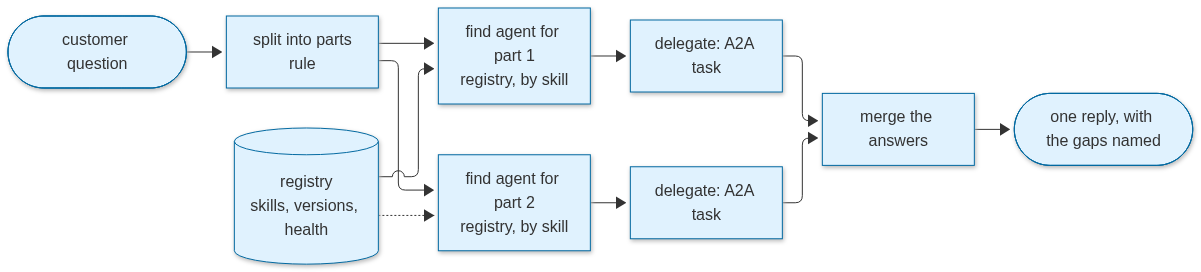

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py, a2a_server.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  Q(["customer question"]) --> S["split into parts<br/>rule"]
  S --> F1["find agent for part 1<br/>registry, by skill"]
  S --> F2["find agent for part 2<br/>registry, by skill"]
  F1 --> D1["delegate: A2A task"] --> J["merge the answers"]
  F2 --> D2["delegate: A2A task"] --> J
  J --> R(["one reply, with the gaps named"])
  REG[("registry<br/>skills, versions, health")] -.-> F1
  REG -.-> F2
  classDef code fill:#e0f2fe,stroke:#0369a1
  class Q,S,F1,F2,D1,D2,J,R,REG code
""")

## Step by step
Five short steps. Steps 1 to 3 build the pieces; steps 4 and 5 send a question through them. No model call is made.

**Step 1 · two agents, each with one skill (no call).** The orders agent looks up the order in code and returns its status. The policy agent
returns a fixed policy text. Both are started as local A2A agents, so each publishes a card. `serve`, `stop` and `send_text` are helpers from
`a2a_server.py`, also in the topic folder: `serve` starts an agent on a free localhost port and returns its address and its server, `stop`
shuts a server down, and `send_text` sends one text message to an agent and returns the events it sent back.
The orders come from `data/support_eval.json`: fictional orders for a made-up shop, written by hand for this course, with no personal data.

In [2]:
import json
from pathlib import Path

from a2a.helpers import get_message_text, new_task_from_user_message, new_text_part
from a2a.server.agent_execution import AgentExecutor
from a2a.server.tasks import TaskUpdater
from a2a.types import a2a_pb2
from a2a_server import serve, stop, send_text

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]
POLICY = "Refunds need a person's approval; returns are accepted within 30 days of delivery."
print("order 1003:", ORDERS["1003"])  # one row of the example data

order 1003: {'status': 'lost', 'days_late': 9, 'total': 89.5}


`AgentExecutor` is the a2a-sdk base class that runs one task. `Agent` below is the one executor both agents share: it answers each task with
the function it was given.

In [3]:
class Agent(AgentExecutor):
    """One executor for both agents: it answers with the function it was given."""

    def __init__(self, answer):
        self.answer = answer

    async def execute(self, context, event_queue):
        task = context.current_task or new_task_from_user_message(context.message)
        if not context.current_task:
            await event_queue.enqueue_event(task)
        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work()
        await updater.add_artifact([new_text_part(self.answer(get_message_text(context.message)))], name="answer")
        await updater.complete()

    async def cancel(self, context, event_queue):
        raise NotImplementedError

The orders agent's answer function reads the order number from the question. Then the two agents are started; keep their servers to stop them
at the end.

In [4]:
def order_status(text: str) -> str:
    digits = [w.strip("?.,") for w in text.split() if w.strip("?.,").isdigit()]
    row = ORDERS.get(digits[0]) if digits else None
    return f"Order {digits[0]} is {row['status']}, {row['days_late']} days late." if row else "No order number was given."


orders_base, orders_server = serve("orders-agent", "Order status.",
                                   [("order_status", "Order status", "The status of one order.")], Agent(order_status))
policy_base, policy_server = serve("policy-agent", "Policy questions.",
                                   [("policy_answer", "Policy answer", "Answers one policy question.")], Agent(lambda _: POLICY))

**Step 2 · the registry (no call).** Each agent is registered with its base, version and skills, and only after a health check: its card is
fetched and has skills. The registry is a LangGraph store, as in lesson 21. The `register` function below does the check and writes the entry.
The third agent is a deliberate failure: nothing listens at its address, so it must be refused.

In [5]:
import httpx
from langgraph.store.memory import InMemoryStore

REGISTRY = InMemoryStore()
NS = ("a2a-registry",)


async def register(name: str, base: str, version: str, owner: str) -> str:
    try:
        async with httpx.AsyncClient(timeout=2.0) as http:
            card = (await http.get(base + "/.well-known/agent-card.json")).json()
    except httpx.HTTPError as error:
        return f"refused {name}: {type(error).__name__}"
    if not card.get("skills"):
        return f"refused {name}: its card lists no skills"
    REGISTRY.put(NS, name, {"base": base, "version": version, "owner": owner,
                            "skills": [s["id"] for s in card["skills"]], "status": "healthy"})
    return f"registered {name} {version}"


print(await register("orders-agent", orders_base, "1.2.0", "orders-team"))
print(await register("policy-agent", policy_base, "2.0.1", "policy-team"))
print(await register("refunds-agent", "http://127.0.0.1:1", "0.1.0", "refunds-team"))  # nothing listens here

registered orders-agent 1.2.0


registered policy-agent 2.0.1
refused refunds-agent: ConnectError


`find_agent` is the lookup the supervisor uses: it returns the first healthy agent that offers the skill, or `None` when no agent does.

In [6]:
def find_agent(skill: str) -> dict | None:
    for item in REGISTRY.search(NS):
        if skill in item.value["skills"] and item.value["status"] == "healthy":
            return {"name": item.key, **item.value}
    return None

**Step 3 · the supervisor graph (no model call).** `split` breaks the question into parts, each with the skill it needs. `delegate` finds the
agent in the registry and sends the part as an A2A task. A part with no agent is reported as a gap. `merge` joins the answers. The graph is
built as a LangGraph `StateGraph`, the same way as in earlier lessons. First, the state and `split`.

In [7]:
from typing import Annotated, TypedDict
import operator

from langgraph.graph import END, START, StateGraph


class SupervisorState(TypedDict):
    question: str
    parts: list
    results: Annotated[list, operator.add]
    reply: str


def split(state: SupervisorState) -> dict:
    parts = []
    if any(w in state["question"].lower() for w in ("where", "status", "late", "parcel", "order")):
        parts.append({"need": "order_status", "text": state["question"]})
    if any(w in state["question"].lower() for w in ("refund", "policy", "return")):
        parts.append({"need": "policy_answer", "text": state["question"]})
    if any(w in state["question"].lower() for w in ("book", "slot")):
        parts.append({"need": "booking", "text": state["question"]})  # no agent offers booking in this lesson
    return {"parts": parts}

Next, `delegate`. For each part it finds the agent, sends the part with `send_text`, and reads the **final state** of the task before it keeps
the text. A task that did not complete is recorded with `ok=False`, so `merge` names it.

In [8]:
async def delegate(state: SupervisorState) -> dict:
    results = []
    for part in state["parts"]:
        agent = find_agent(part["need"])
        if agent is None:
            results.append({"need": part["need"], "ok": False, "text": "no healthy agent offers this skill"})
            continue
        events = await send_text(agent["base"], part["text"])
        final = [e for e in events if e.HasField("task")][-1].task
        state_name = a2a_pb2.TaskState.Name(final.status.state)
        text = final.artifacts[0].parts[0].text if final.artifacts else ""
        results.append({"need": part["need"], "agent": agent["name"], "ok": state_name == "TASK_STATE_COMPLETED", "text": text})
    return {"results": results}

Last, `merge` and the graph. `show_graph` is another helper from `graph_view.py`: it draws a compiled LangGraph graph, so you can check the
wiring.

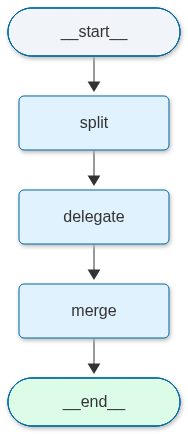

In [9]:
def merge(state: SupervisorState) -> dict:
    done = [r["text"] for r in state["results"] if r["ok"]]
    gaps = [r["need"] for r in state["results"] if not r["ok"]]
    reply = " ".join(done) + (f" (Could not get an answer for: {', '.join(gaps)}.)" if gaps else "")
    return {"reply": reply}


graph = StateGraph(SupervisorState)
graph.add_node("split", split)
graph.add_node("delegate", delegate)
graph.add_node("merge", merge)
graph.add_edge(START, "split").add_edge("split", "delegate").add_edge("delegate", "merge").add_edge("merge", END)
supervisor = graph.compile()
from graph_view import show_graph
show_graph(supervisor)

**Step 4 · a question that needs two agents (no call).** One customer question, two parts, two agents. The supervisor sends each part to the agent
the registry names, and the reply holds both answers.

In [10]:
out = await supervisor.ainvoke({"question": "Where is order 1003, and what is your refund policy?", "parts": [], "results": [], "reply": ""})
for r in out["results"]:
    print(f"{r['need']:<14} via {r.get('agent', '-'):<14} ok={r['ok']} · {r['text'][:70]}")
print("reply:", out["reply"])

order_status   via orders-agent   ok=True · Order 1003 is lost, 9 days late.
policy_answer  via policy-agent   ok=True · Refunds need a person's approval; returns are accepted within 30 days 
reply: Order 1003 is lost, 9 days late. Refunds need a person's approval; returns are accepted within 30 days of delivery.


**Step 5 · a question whose agent is missing (no call).** A question about booking a delivery slot needs a skill that no registered agent
offers. The reply answers the order part and names the booking gap, rather than guessing.

In [11]:
out = await supervisor.ainvoke({"question": "Please book a delivery slot for order 1003.", "parts": [], "results": [], "reply": ""})
print("reply:", out["reply"])
stop(orders_server)
stop(policy_server)

reply: Order 1003 is lost, 9 days late. (Could not get an answer for: booking.)


## At work
- A registry is what makes a new agent reachable without a release. The registry check runs at registration and again on a schedule →
  lesson 21 (registry) and lesson 35 (reliability).
- The supervisor names the gaps. A customer who gets a partial answer with the gap named can ask again; one who gets a guess cannot check it.
- A delegated task is a contract with another team's agent. Teams log every task, its state and its owner → lesson 33 (observability).

## What just happened
- Step 2 registered `orders-agent 1.2.0` and `policy-agent 2.0.1`. It refused `refunds-agent` with `ConnectError`, because nothing listens at
  its address, so it never reached the registry.
- Step 4 printed two parts, each with `ok=True`: `order_status` via `orders-agent` and `policy_answer` via `policy-agent`. The reply joins both answers.
- Step 5 printed the reply `Order 1003 is lost, 9 days late. (Could not get an answer for: booking.)`. The order part is answered and the booking gap is named.
- No registered agent offers `booking`, so `find_agent("booking")` returned `None`, and that part became the gap.

## Common mistakes
Each mistake below runs the wrong code first. The error it prints is real.

1. **Routing by name.** Names change. Route by skill id, as `find_agent` does. This code looks up an agent by a name that was renamed:

In [12]:
try:
    REGISTRY.get(NS, "order-agent")["base"]  # the agent is called orders-agent
except Exception as error:
    print(f"mistake 1: {type(error).__name__} {str(error).splitlines()[0]}")

mistake 1: TypeError 'NoneType' object is not subscriptable


The fix is to ask the registry by skill with `find_agent("order_status")`, which does not depend on the name.

2. **Merging states you did not read.** A task can end in failed or canceled. Read each final state before you merge its text. This code
reads the text of a failed task that has no artifact:

In [13]:
failed = a2a_pb2.Task()
failed.status.state = a2a_pb2.TaskState.TASK_STATE_FAILED
try:
    print(failed.artifacts[0].parts[0].text)
except Exception as error:
    print(f"mistake 2: {type(error).__name__} {str(error).splitlines()[0]}")

mistake 2: IndexError list index out of range


The fix is to read the state first, as `delegate` does: `a2a_pb2.TaskState.Name(failed.status.state)` gives `TASK_STATE_FAILED`, and only a
completed task's text is merged.

In [14]:
print(a2a_pb2.TaskState.Name(failed.status.state), "-> not merged")

TASK_STATE_FAILED -> not merged


3. **Silent gaps.** A part with no agent must appear in the reply. Otherwise the customer thinks the question was answered. This code uses the
result of `find_agent` without checking it:

In [15]:
agent = find_agent("booking")  # no agent offers booking
try:
    print(agent["base"])
except Exception as error:
    print(f"mistake 3: {type(error).__name__} {str(error).splitlines()[0]}")

mistake 3: TypeError 'NoneType' object is not subscriptable


The fix is the check `delegate` makes: if `find_agent` returns `None`, record the part as a gap and name it in the reply.

In [16]:
if agent is None:
    print("gap recorded: booking")

gap recorded: booking


## Try it
Write `gaps(results)` that returns the list of skill ids (the `need` field) whose result has `ok` set to `False`. Test it on `out["results"]` from
Step 5. No model call is needed.

In [17]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [18]:
def gaps(results: list[dict]) -> list[str]:
    return [r["need"] for r in results if not r["ok"]]


print(gaps(out["results"]))  # ['booking']

['booking']


## Key terms
- **Supervisor** — the agent that splits a request into parts, delegates each part and merges the answers.
- **Delegation** — sending one part of a job to another agent as an A2A task, and reading that task's final state.
- **Skill** — the id in an agent's card that names one thing the agent can do; the registry is searched by it.
- **Gap** — a part of the question that no healthy agent answered; it is named in the reply.
- **Health check** — the test a registration must pass: the agent's card is fetched and lists at least one skill.

## Recap
- A registry lists A2A agents by skill, with version, owner and health; an agent is registered only after its card passes.
- A supervisor splits the question, finds the agent for each part, delegates each part as a task, and merges the answers.
- A part with no agent is named in the reply, and each task's final state is read before its text is used.

**Interview:** "A customer question needs two specialist agents. How do you route it, and what does the customer see when one is down?" Strong answer:
"A supervisor splits the question, looks up each part in a registry by skill, and delegates each part as a task. If an agent is down or its task
did not complete, the reply names that part as not answered."